<a href="https://colab.research.google.com/github/SanviBallal/Factory-Shipping-Optimization/blob/main/03_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("/content/Nassau Candy Distributor.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!
Shape: (10194, 18)

First 5 records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90



Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']


In [2]:
# General information about the dataset
df.info()

print("\nStatistical summary:")
display(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

,Row ID,Customer ID,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,134468.961154,13.908537,3.791838,9.166451,4.742087
std,2942.898656,20231.483007,11.341020,2.228317,6.643740,5.061647
min,1.000000,100006.000000,1.250000,1.000000,0.250000,0.600000
25%,2549.250000,117212.000000,7.200000,2.000000,4.900000,2.400000
50%,5097.500000,133550.000000,10.800000,3.000000,7.470000,3.600000
75%,7645.750000,152051.000000,18.000000,5.000000,12.250000,5.700000
max,10194.000000,192314.000000,260.000000,14.000000,130.000000,130.000000


In [3]:
# Calculate overall business performance
total_sales = df["Sales"].sum()
total_cost = df["Cost"].sum()
total_profit = df["Gross Profit"].sum()

profit_margin = (total_profit / total_sales) * 100

print("OVERALL BUSINESS PERFORMANCE")
print("--------------------------------")

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Cost: ${total_cost:,.2f}")
print(f"Total Gross Profit: ${total_profit:,.2f}")
print(f"Gross Profit Margin: {profit_margin:.2f}%")


OVERALL BUSINESS PERFORMANCE
--------------------------------
Total Sales: $141,783.63
Total Cost: $48,340.83
Total Gross Profit: $93,442.80
Gross Profit Margin: 65.91%


In [4]:

# Product-wise sales and profit analysis
product_analysis = (
    df.groupby("Product Name")
    .agg({
        "Sales": "sum",
        "Units": "sum",
        "Gross Profit": "sum",
        "Cost": "sum"
    })
    .sort_values(by="Sales", ascending=False)
)

print("PRODUCT-WISE PERFORMANCE")
display(product_analysis.round(2))


PRODUCT-WISE PERFORMANCE


,Sales,Units,Gross Profit,Cost
Product Name,,,,
Wonka Bar - Triple Dazzle Caramel,28485.00,7596,18610.20,9874.80
Wonka Bar -Scrumdiddlyumptious,27874.80,7743,19357.50,8517.30
Wonka Bar - Milk Chocolate,26867.75,8267,17443.37,9424.38
Wonka Bar - Fudge Mallows,24890.40,6914,16593.60,8296.80
Wonka Bar - Nutty Crunch Surprise,23574.95,6755,16819.95,6755.00
Lickable Wallpaper,7860.00,393,3930.00,3930.00
Kazookles,1205.75,371,92.75,1113.00
Wonka Gum,597.50,478,310.70,286.80
Everlasting Gobstopper,130.00,13,104.00,26.00


In [5]:
region_analysis = (
    df.groupby("Region")
    .agg({
        "Sales": "sum",
        "Units": "sum",
        "Gross Profit": "sum",
        "Cost": "sum"
    })
    .sort_values(by="Sales", ascending=False)
)

print("REGION-WISE PERFORMANCE")
display(region_analysis.round(2))

REGION-WISE PERFORMANCE


,Sales,Units,Gross Profit,Cost
Region,,,,
Pacific,46301.53,12466,30485.94,15815.59
Atlantic,41197.24,11159,26973.70,14223.54
Interior,32037.60,8820,21282.49,10755.11
Gulf,22247.26,6209,14700.67,7546.59


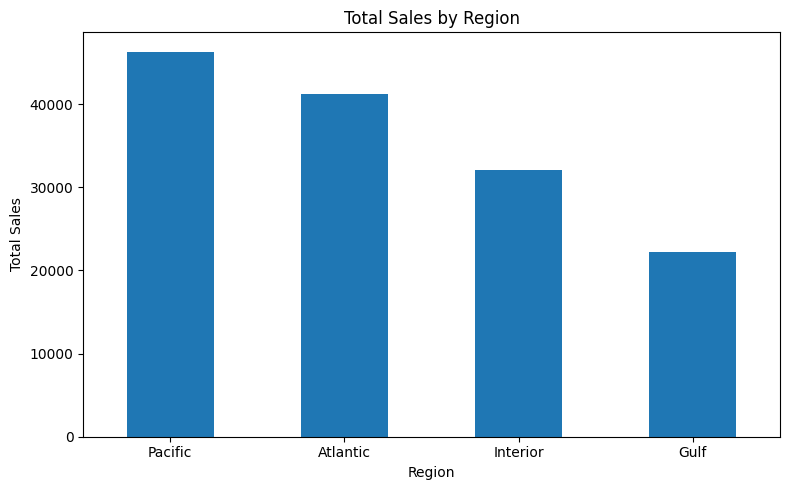

In [6]:
plt.figure(figsize=(8, 5))

region_analysis["Sales"].plot(
    kind="bar",
    title="Total Sales by Region"
)

plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

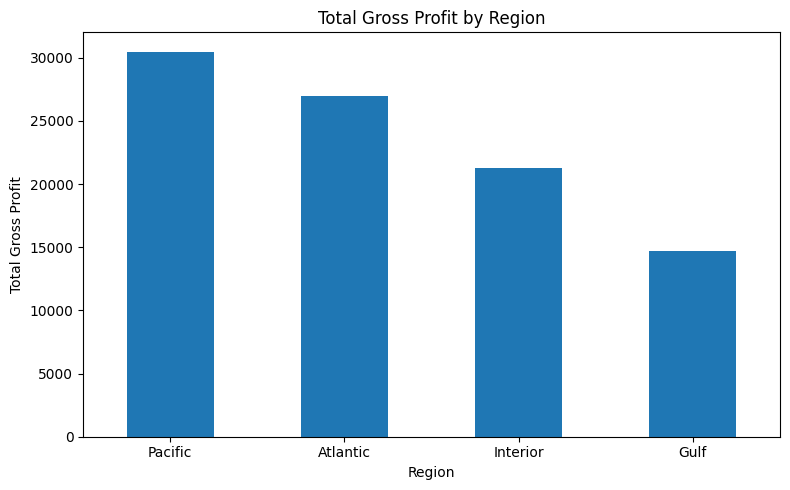

In [7]:
plt.figure(figsize=(8, 5))

region_analysis["Gross Profit"].plot(
    kind="bar",
    title="Total Gross Profit by Region"
)

plt.xlabel("Region")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
region_analysis["Profit Margin (%)"] = (
    region_analysis["Gross Profit"] / region_analysis["Sales"]
) * 100

display(region_analysis.round(2))

,Sales,Units,Gross Profit,Cost,Profit Margin (%)
Region,,,,,
Pacific,46301.53,12466,30485.94,15815.59,65.84
Atlantic,41197.24,11159,26973.70,14223.54,65.47
Interior,32037.60,8820,21282.49,10755.11,66.43
Gulf,22247.26,6209,14700.67,7546.59,66.08


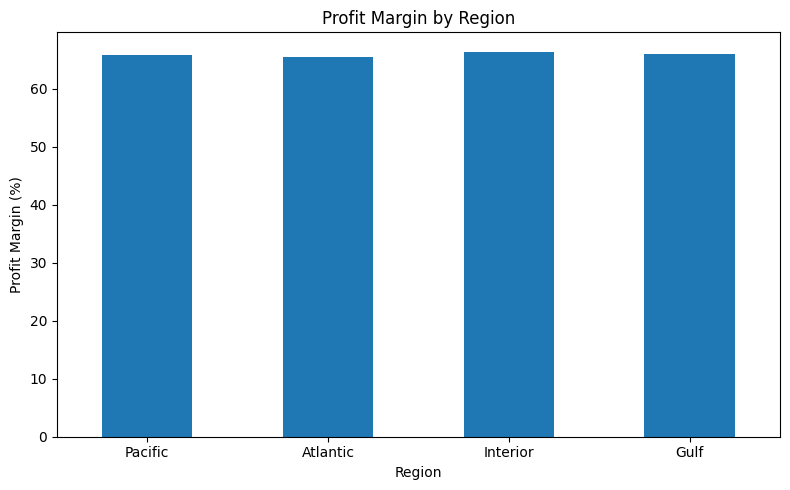

In [10]:
plt.figure(figsize=(8, 5))

region_analysis["Profit Margin (%)"].plot(
    kind="bar",
    title="Profit Margin by Region"
)

plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
division_analysis = (
    df.groupby("Division")
    .agg({
        "Sales": "sum",
        "Units": "sum",
        "Gross Profit": "sum",
        "Cost": "sum"
    })
    .sort_values(by="Sales", ascending=False)
)

print("DIVISION-WISE PERFORMANCE")
display(division_analysis.round(2))


DIVISION-WISE PERFORMANCE


,Sales,Units,Gross Profit,Cost
Division,,,,
Chocolate,131692.90,37275,88824.62,42868.28
Other,9663.25,1242,4333.45,5329.80
Sugar,427.48,137,284.73,142.75


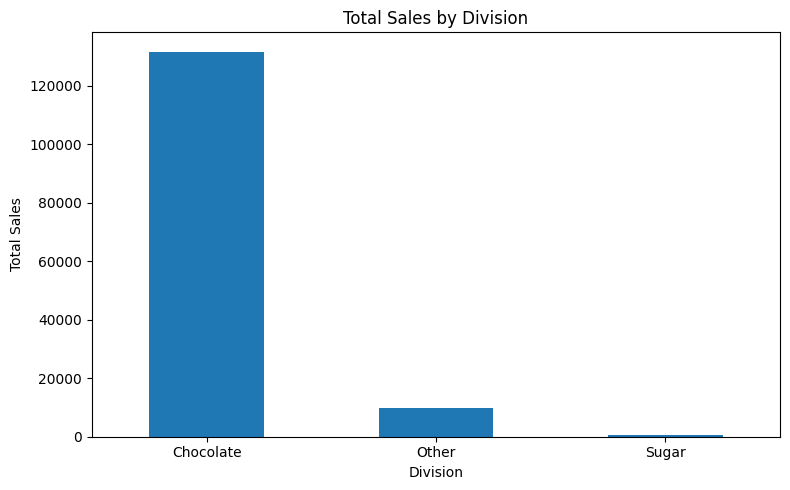

In [12]:
plt.figure(figsize=(8, 5))

division_analysis["Sales"].plot(
    kind="bar",
    title="Total Sales by Division"
)

plt.xlabel("Division")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:
division_analysis["Profit Margin (%)"] = (
    division_analysis["Gross Profit"] / division_analysis["Sales"]
) * 100

print("DIVISION-WISE PROFIT MARGIN")
display(division_analysis.round(2))

DIVISION-WISE PROFIT MARGIN


,Sales,Units,Gross Profit,Cost,Profit Margin (%)
Division,,,,,
Chocolate,131692.90,37275,88824.62,42868.28,67.45
Other,9663.25,1242,4333.45,5329.80,44.84
Sugar,427.48,137,284.73,142.75,66.61


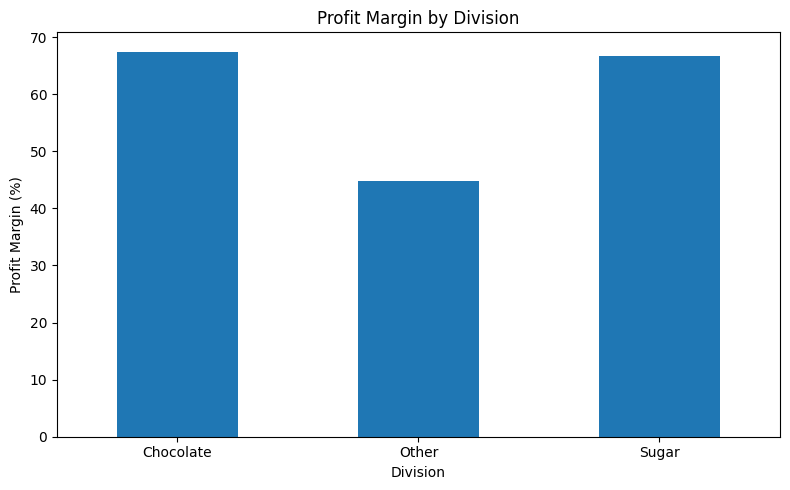

In [14]:
plt.figure(figsize=(8, 5))

division_analysis["Profit Margin (%)"].plot(
    kind="bar",
    title="Profit Margin by Division"
)

plt.xlabel("Division")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
print(df["Order Date"].head())
print(df["Order Date"].dtype)

0    03-01-2024
1    04-01-2024
2    04-01-2024
3    04-01-2024
4    05-01-2024
Name: Order Date, dtype: object
object


In [16]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True
)

df["Year"] = df["Order Date"].dt.year

yearly_analysis = (
    df.groupby("Year")
    .agg({
        "Sales": "sum",
        "Units": "sum",
        "Gross Profit": "sum",
        "Cost": "sum"
    })
)

print("YEAR-WISE BUSINESS PERFORMANCE")
display(yearly_analysis.round(2))

YEAR-WISE BUSINESS PERFORMANCE


,Sales,Units,Gross Profit,Cost
Year,,,,
2024,57956.20,15899,38151.43,19804.77
2025,83827.43,22755,55291.37,28536.06


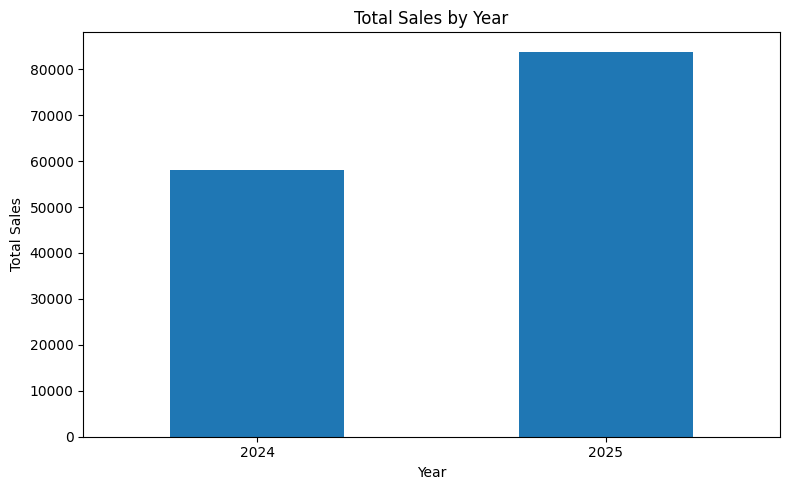

In [17]:
plt.figure(figsize=(8, 5))

yearly_analysis["Sales"].plot(
    kind="bar",
    title="Total Sales by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
sales_2024 = yearly_analysis.loc[2024, "Sales"]
sales_2025 = yearly_analysis.loc[2025, "Sales"]

growth = ((sales_2025 - sales_2024) / sales_2024) * 100

print(f"Sales Growth (2024 to 2025): {growth:.2f}%")

Sales Growth (2024 to 2025): 44.64%


In [19]:
shipping_analysis = (
    df.groupby("Ship Mode")
    .agg({
        "Sales": "sum",
        "Units": "sum",
        "Gross Profit": "sum",
        "Cost": "sum",
        "Order ID": "count"
    })
    .rename(columns={"Order ID": "Number of Records"})
    .sort_values(by="Number of Records", ascending=False)
)

print("SHIPPING-MODE PERFORMANCE")
display(shipping_analysis.round(2))

SHIPPING-MODE PERFORMANCE


,Sales,Units,Gross Profit,Cost,Number of Records
Ship Mode,,,,,
Standard Class,85490.35,23409,56424.46,29065.89,6120
Second Class,27860.22,7546,18306.52,9553.70,1979
First Class,21319.39,5724,14011.09,7308.30,1548
Same Day,7113.67,1975,4700.73,2412.94,547


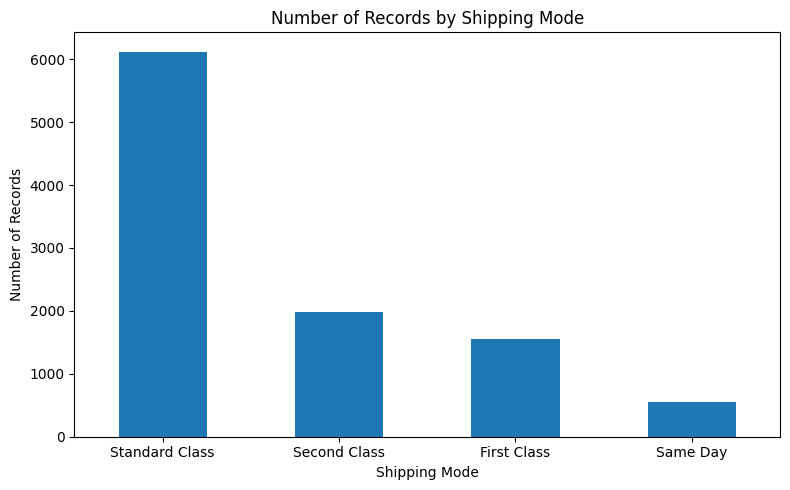

In [20]:
plt.figure(figsize=(8, 5))

shipping_analysis["Number of Records"].plot(
    kind="bar",
    title="Number of Records by Shipping Mode"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_analysis = (
    df.groupby("Month")["Sales"]
    .sum()
)

print("MONTHLY SALES PERFORMANCE")
display(monthly_analysis)

MONTHLY SALES PERFORMANCE


,Sales
Month,
2024-01,2093.90
2024-02,1379.87
2024-03,4138.90
2024-04,3988.22
2024-05,3951.52
2024-06,3518.76
2024-07,3865.38
2024-08,4477.65
2024-09,7912.10


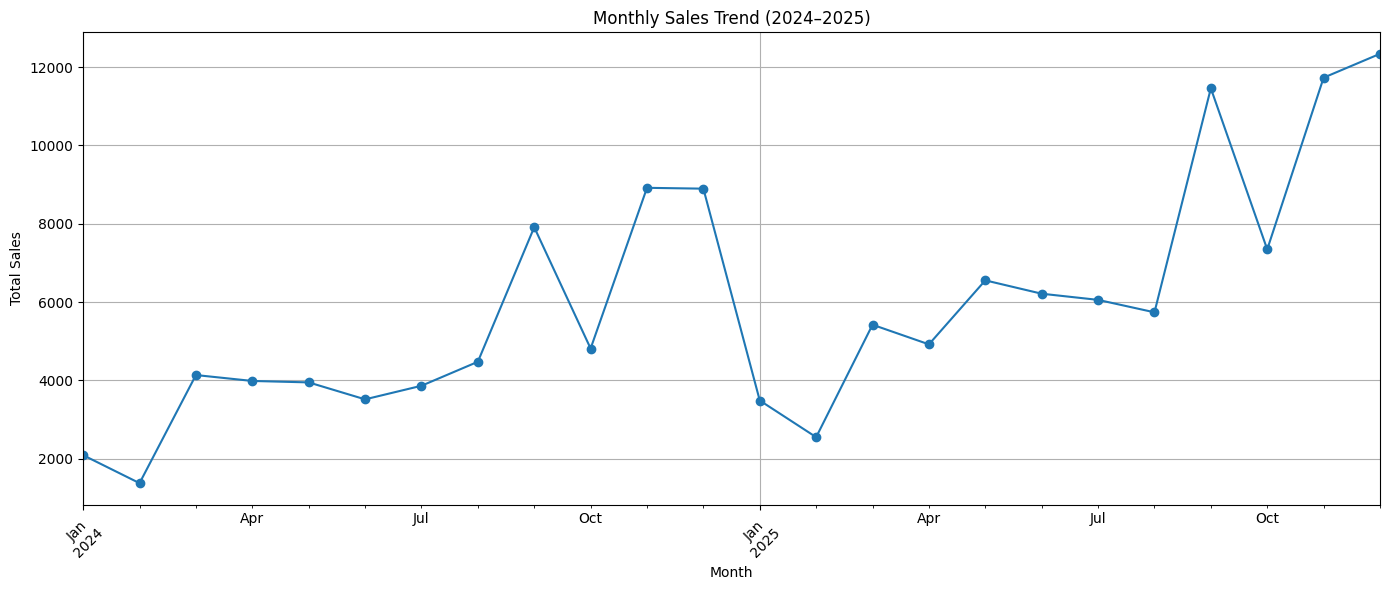

In [22]:
plt.figure(figsize=(14, 6))

monthly_analysis.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend (2024–2025)"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Day 3: Exploratory Data Analysis – Overall Findings and Conclusion

## 1. Overall Business Performance
- Total Sales: 141,783.63
- Total Cost: 48,340.83
- Total Gross Profit: 93,442.80
- Overall Gross Profit Margin: 65.91%

The business generated a gross profit margin of approximately 65.91%, indicating a strong overall gross profit contribution.

## 2. Product-Wise Analysis
- Wonka Bar – Triple Dazzle Caramel recorded the highest sales (28,485.00).
- Wonka Bar – Scrumdiddlyumptious generated the highest gross profit (19,357.50).
- Wonka Bar – Milk Chocolate recorded the highest units sold (8,267).
- The five Wonka Bar products contributed the majority of business sales and gross profit.
- Kazookles recorded a relatively low gross profit compared with its sales.

## 3. Region-Wise Analysis
- Pacific recorded the highest sales (46,301.53) and gross profit (30,485.94).
- Atlantic ranked second in sales (41,197.24).
- Gulf recorded the lowest sales (22,247.26).
- Interior achieved the highest regional profit margin (66.43%).
- All four regions had relatively similar profit margins, ranging from 65.47% to 66.43%.

## 4. Division-Wise Analysis
- Chocolate dominated the business with sales of 131,692.90.
- Chocolate contributed approximately 92.9% of total sales.
- Chocolate also recorded the highest gross profit (88,824.62).
- Chocolate had the highest profit margin (67.45%).
- The Other division had the lowest profit margin (44.84%).

## 5. Year-Wise Analysis
- Total sales in 2024: 57,956.20.
- Total sales in 2025: 83,827.43.
- Sales increased by approximately 44.64% from 2024 to 2025.
- The yearly comparison indicates an increase in business sales during 2025.

## 6. Shipping-Mode Analysis
- Standard Class was the most frequently used shipping mode, with 6,120 records.
- It also generated the highest sales (85,490.35) and gross profit (56,424.46).
- Same Day was the least frequently used shipping mode, with 547 records.
- Standard Class accounted for approximately 60% of all dataset records.

## 7. Monthly Sales Analysis
- Monthly sales were generally higher during 2025 compared with 2024.
- December 2025 recorded the highest monthly sales (12,338.27).
- February 2024 recorded the lowest monthly sales (1,379.87).
- September, November and December 2025 showed particularly strong sales.

## 8. Overall Conclusion

The exploratory data analysis reveals that the Chocolate division and Wonka Bar products contribute the largest share of business performance. The Pacific region leads in total sales and gross profit, while Interior has the highest regional profit margin.

Sales increased by 44.64% in 2025 compared with 2024. Standard Class is the most commonly used shipping mode. Monthly analysis also indicates stronger sales towards the final months of 2025.

These findings provide a useful foundation for the next stages of the project, particularly factory-to-customer distance analysis, product-to-factory mapping, factory allocation and shipping optimization.

**Data Limitation:** The earlier data-quality investigation identified unusually large shipping lead times. Therefore, shipping-date information should not be treated as reliable for predictive modelling until its accuracy is independently verified.

**Final Outcome:** Day 3 exploratory data analysis is completed. The findings will be used to guide the development of the factory reallocation and shipping optimization recommendation system.